# Topic 13 — Predicting Caravan Insurance Ownership

**Objective.** Develop a classification model to predict whether a customer holds a caravan insurance policy, using the Insurance Company Benchmark (COIL 2000) dataset.

- **Predictors:** 85 coded variables describing neighbourhood demographics and customers' existing insurance products.
- **Target variable:** `CARAVAN` (1 = holds a caravan insurance policy; 0 = does not).
- **Primary evaluation metric:** Average Precision (AP), given the low prevalence of the positive class.
- **Evaluation protocol:** Retain the official UCI training–test split. Use the labelled training data for exploratory analysis, feature screening, model selection, and hyperparameter tuning. Evaluate the selected model on the official test set only once.



## 1. Dataset and Evaluation Protocol

We use the **official UCI data split** to ensure that results are comparable across groups. The dataset contains 5,822 labelled training observations (`ticdata2000.txt`), 4,000 official test observations (`ticeval2000.txt`), and the corresponding test labels (`tictgts2000.txt`), all obtained from the UCI KDD archive.

Immediately after loading the data, we divide the official training set into a development subset (80%) and a validation subset (20%). Supervised exploratory analysis and model development are conducted using the development subset only. The validation subset is used exclusively to compare candidate models and select the final configuration.

The official test features are transformed only with preprocessing fitted on the development data. The official test labels remain untouched until the final evaluation (Section 7).



In [1]:
import os
RANDOM_SEED = 42
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 30)


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
BASE_URL = "https://kdd.ics.uci.edu/databases/tic"

for filename in ["ticdata2000.txt", "ticeval2000.txt", "tictgts2000.txt"]:
    path = DATA_DIR / filename
    if not path.exists():
        urlretrieve(f"{BASE_URL}/{filename}", path)

print("Downloaded / found:", sorted(p.name for p in DATA_DIR.glob("*.txt")))


Downloaded / found: ['ticdata2000.txt', 'ticeval2000.txt', 'tictgts2000.txt']


In [3]:
names = '''MOSTYPE MAANTHUI MGEMOMV MGEMLEEF MOSHOOFD MGODRK MGODPR MGODOV MGODGE MRELGE MRELSA MRELOV
MFALLEEN MFGEKIND MFWEKIND MOPLHOOG MOPLMIDD MOPLLAAG MBERHOOG MBERZELF MBERBOER MBERMIDD MBERARBG
MBERARBO MSKA MSKB1 MSKB2 MSKC MSKD MHHUUR MHKOOP MAUT1 MAUT2 MAUT0 MZFONDS MZPART MINKM30 MINK3045
MINK4575 MINK7512 MINK123M MINKGEM MKOOPKLA PWAPART PWABEDR PWALAND PPERSAUT PBESAUT PMOTSCO PVRAAUT
PAANHANG PTRACTOR PWERKT PBROM PLEVEN PPERSONG PGEZONG PWAOREG PBRAND PZEILPL PPLEZIER PFIETS PINBOED
PBYSTAND AWAPART AWABEDR AWALAND APERSAUT ABESAUT AMOTSCO AVRAAUT AAANHANG ATRACTOR AWERKT ABROM
ALEVEN APERSONG AGEZONG AWAOREG ABRAND AZEILPL APLEZIER AFIETS AINBOED ABYSTAND'''.split()

# Load the official COIL 2000 split. Both frames share exactly the same schema.
train_df = pd.read_csv("data/ticdata2000.txt", sep="\t", header=None,
                       names=names + ["CARAVAN"])
test_features = pd.read_csv("data/ticeval2000.txt", sep="\t", header=None,
                            names=names)
test_labels = pd.read_csv("data/tictgts2000.txt", sep="\t", header=None,
                          names=["CARAVAN"])
test_df = test_features.copy()
test_df["CARAVAN"] = test_labels["CARAVAN"].to_numpy()
test_df = test_df[train_df.columns]  # identical column order

X_full_train = train_df.drop(columns="CARAVAN").copy()
y_full_train = train_df["CARAVAN"].astype(int).copy()
X_test = test_df.drop(columns="CARAVAN").copy()
y_test = test_df["CARAVAN"].astype(int).copy()

# Split raw official training rows BEFORE any supervised EDA or learned preprocessing.
# Keep the full official training set untouched for the final refit after model selection.
from sklearn.model_selection import train_test_split
X_dev_raw, X_val_raw, y_dev, y_val = train_test_split(
    X_full_train, y_full_train, test_size=0.20,
    stratify=y_full_train, random_state=RANDOM_SEED,
)
# In Sections 2–4, X/y refer to development rows only.
X = X_dev_raw.copy()
y = y_dev.copy()

M, P, A = names[:43], names[43:64], names[64:]
nominal = ["MOSTYPE", "MOSHOOFD"]

assert list(train_df.columns) == list(test_df.columns)
assert X_full_train.shape[1] == 85 and len(X_test) == 4000
assert len(X_dev_raw) + len(X_val_raw) == len(X_full_train)
assert X_dev_raw.index.intersection(X_val_raw.index).empty
assert set(X_dev_raw.index).isdisjoint(set(X_val_raw.index))
assert y_dev.index.equals(X_dev_raw.index) and y_val.index.equals(X_val_raw.index)
print(f"Official training: {train_df.shape}; official test: {test_df.shape}")
print(f"Development: {X_dev_raw.shape}, positive rate={y_dev.mean():.2%}; "
      f"validation: {X_val_raw.shape}, positive rate={y_val.mean():.2%}")
print(f"Official test positive rate is reserved for final evaluation: {y_test.mean():.2%}")
display(train_df.head())


Official training: (5822, 86); official test: (4000, 86)
Development: (4657, 85), positive rate=5.97%; validation: (1165, 85), positive rate=6.01%
Official test positive rate is reserved for final evaluation: 5.95%


,MOSTYPE,MAANTHUI,MGEMOMV,MGEMLEEF,MOSHOOFD,MGODRK,MGODPR,MGODOV,MGODGE,MRELGE,MRELSA,MRELOV,MFALLEEN,MFGEKIND,MFWEKIND,...,AAANHANG,ATRACTOR,AWERKT,ABROM,ALEVEN,APERSONG,AGEZONG,AWAOREG,ABRAND,AZEILPL,APLEZIER,AFIETS,AINBOED,ABYSTAND,CARAVAN
0,33,1,3,2,8,0,5,1,3,7,0,2,1,2,6,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
1,37,1,2,2,8,1,4,1,4,6,2,2,0,4,5,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
2,37,1,2,2,8,0,4,2,4,3,2,4,4,4,2,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
3,9,1,3,3,3,2,3,2,4,5,2,2,2,3,4,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
4,40,1,4,2,10,1,4,1,4,7,1,2,2,4,4,...,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0


### Working datasets and partitions

The following variables are used throughout the notebook:

- `train_df`, `test_df`: the loaded training and official test data.
- `X_full_train`, `y_full_train`: predictors and target from the complete labelled training set.
- `X_test`, `y_test`: predictors and target from the official test set.
- `X_dev_raw`, `y_dev`: predictors and target for the development subset.
- `X_val_raw`, `y_val`: predictors and target for the validation subset.



## 2. Dataset Description

The 85 predictors are organised into three main groups, as summarised below.

| Group | Number of columns | Unit of measurement | Description and coding |
|---|---:|---|---|
| `M…` socio-demographic variables | 43 | Customer's **neighbourhood** (postcode area), rather than the individual customer | Most variables are encoded as percentage bands of unequal width: 0 = 0%, 1 = 1–10%, 2 = 11–23%, 3 = 24–36%, …, 8 = 89–99%, and 9 = 100%. Exceptions include `MAANTHUI` (number of houses), `MGEMOMV` (average household size), `MGEMLEEF` (age band), and `MKOOPKLA` (purchasing-power class, 1–8). |
| `MOSTYPE`, `MOSHOOFD` | 2 (included in the `M…` group) | Neighbourhood | Nominal variables representing 41 customer subtypes and 10 main customer types, respectively. |
| `P…` product-premium variables | 21 | Individual customer | Premium bands in Dutch guilders (f): 0 = none, 1 = f1–49, 2 = f50–99, 3 = f100–199, 4 = f200–499, 5 = f500–999, 6 = f1,000–4,999, 7 = f5,000–9,999, 8 = f10,000–19,999, and 9 = ≥ f20,000. |
| `A…` product-count variables | 21 | Individual customer | Number of policies held for the corresponding 21 insurance products. |
| `CARAVAN` | Target | Individual customer | 1 = holds a caravan insurance policy; 0 = does not. |



In [4]:
print(f'development: {X.shape}, official test: {X_test.shape}, missing values: {X.isna().sum().sum() + X_test.isna().sum().sum()}')
print(f'owners: development {y.sum()} ({y.mean():.1%}); official test labels are reserved for final evaluation')

development: (4657, 85), official test: (4000, 85), missing values: 0
owners: development 278 (6.0%); official test labels are reserved for final evaluation


## 3. Exploratory Data Analysis

### 3.1 Association Between Predictors and Caravan Insurance Ownership

For each predictor, we perform a **chi-square ($\chi^2$) test of independence** to examine its association with the target variable, `CARAVAN`.

Testing 85 predictors at a significance level of $\alpha = 0.05$ would produce approximately four false positives by chance alone. To account for multiple comparisons, we adjust the p-values using the **Benjamini–Hochberg procedure**, which controls the false discovery rate (the expected proportion of false positives among the features identified as significant).

The adjusted $q$-values are used for feature screening and ranking. These results should be interpreted with some caution because categories containing very few observations may weaken the reliability of the chi-square approximation.



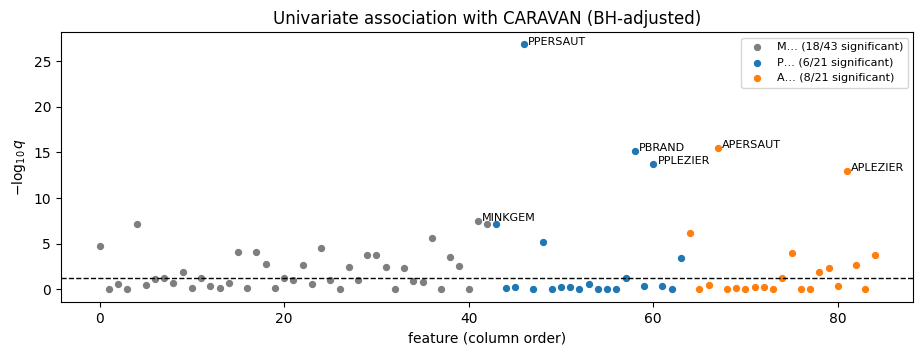

In [5]:
from scipy.stats import chi2_contingency, false_discovery_control

group = pd.Series(['M'] * 43 + ['P'] * 21 + ['A'] * 21, index=names)
q = pd.Series(false_discovery_control([chi2_contingency(pd.crosstab(X[c], y))[1] for c in names]), index=names)

fig, ax = plt.subplots(figsize=(11, 3.5))
for g, c in zip('MPA', ['tab:gray', 'tab:blue', 'tab:orange']):
    idx = np.flatnonzero(group == g)
    ax.scatter(idx, -np.log10(q.iloc[idx]), c=c, s=18, label=f'{g}… ({(q.iloc[idx] < 0.05).sum()}/{len(idx)} significant)')
for c in q.nsmallest(6).index:
    ax.annotate(c, (names.index(c), -np.log10(q[c])), fontsize=8, xytext=(3, 0), textcoords='offset points')
ax.axhline(-np.log10(0.05), c='k', ls='--', lw=1)
ax.set(xlabel='feature (column order)', ylabel='$-\\log_{10} q$', title='Univariate association with CARAVAN (BH-adjusted)')
ax.legend(fontsize=8)
plt.show()

Product-related variables show the strongest individual associations with caravan insurance ownership, particularly car insurance premium (`PPERSAUT`), fire insurance (`PBRAND`), and boat insurance (`PPLEZIER`). However, several neighbourhood-level variables are also statistically significant, with purchasing power (`MKOOPKLA`), customer type (`MOSHOOFD`), and income-related variables among the leading factors.

By contrast, most product variables show no statistically significant association with the target. This may be because the corresponding products are held by relatively few customers.



### 3.2 Examining the Shape of the Associations



In [6]:
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

# Use BH-adjusted q-values consistently with Section 3.1.
p_values = pd.Series(
    [stats.chi2_contingency(pd.crosstab(X[c], y))[1] for c in names],
    index=names
)
q_values = pd.Series(multipletests(p_values.values, method="fdr_bh")[1], index=names)
significant_features = list(q_values[q_values < 0.05].index)
print(f"Features significant after BH correction (q < 0.05): {len(significant_features)}")
print(significant_features)


Features significant after BH correction (q < 0.05): 32
['MOSTYPE', 'MOSHOOFD', 'MRELGE', 'MOPLHOOG', 'MOPLLAAG', 'MBERHOOG', 'MBERARBG', 'MSKA', 'MSKC', 'MHHUUR', 'MHKOOP', 'MAUT1', 'MAUT0', 'MINKM30', 'MINK4575', 'MINK7512', 'MINKGEM', 'MKOOPKLA', 'PWAPART', 'PPERSAUT', 'PMOTSCO', 'PBRAND', 'PPLEZIER', 'PBYSTAND', 'AWAPART', 'APERSAUT', 'ALEVEN', 'AWAOREG', 'ABRAND', 'APLEZIER', 'AFIETS', 'ABYSTAND']


In [7]:
# Assess monotonicity only for ordinal/numeric-coded features; nominal variables are not ordered.
monotonicity_results = []
nominal_features = {"MOSTYPE", "MOSHOOFD"}

for col in significant_features:
    if col in nominal_features:
        monotonicity_results.append({
            "Feature": col, "Group": group[col], "Spearman": np.nan,
            "Is_Monotonic": "Not applicable (nominal)", "Trend": "Nominal"
        })
        continue

    group_stats = y.groupby(X[col]).agg(["count", "mean"]).reset_index()
    group_stats = group_stats[group_stats["count"] >= 5]
    if len(group_stats) > 1:
        spearman_corr, _ = stats.spearmanr(group_stats[col], group_stats["mean"])
    else:
        spearman_corr = np.nan

    # Descriptive heuristic only; do not interpret this as a formal test of monotonicity.
    is_monotonic = "Yes" if pd.notna(spearman_corr) and abs(spearman_corr) >= 0.8 else "No"
    trend = ("Increasing" if spearman_corr >= 0.8 else
             "Decreasing" if spearman_corr <= -0.8 else "Not clearly monotonic")
    monotonicity_results.append({
        "Feature": col, "Group": group[col], "Spearman": spearman_corr,
        "Is_Monotonic": is_monotonic, "Trend": trend
    })

monotonicity_df = pd.DataFrame(monotonicity_results)
display(monotonicity_df)


,Feature,Group,Spearman,Is_Monotonic,Trend
0,MOSTYPE,M,NaN,Not applicable (nominal),Nominal
1,MOSHOOFD,M,NaN,Not applicable (nominal),Nominal
2,MRELGE,M,0.842424,Yes,Increasing
3,MOPLHOOG,M,0.648485,No,Not clearly monotonic
4,MOPLLAAG,M,-0.878788,Yes,Decreasing
5,MBERHOOG,M,0.709091,No,Not clearly monotonic
6,MBERARBG,M,0.248485,No,Not clearly monotonic
7,MSKA,M,0.296970,No,Not clearly monotonic
8,MSKC,M,-0.357576,No,Not clearly monotonic
9,MHHUUR,M,-0.854545,Yes,Decreasing


In [8]:
# Features not classified as monotonic; nominal features are excluded from this interpretation.
non_monotonic_features = monotonicity_df.loc[
    monotonicity_df["Is_Monotonic"].eq("No"), "Feature"
].tolist()
print(f"Features classified as not clearly monotonic: {len(non_monotonic_features)}")
print(non_monotonic_features)
print("Note: this is a descriptive heuristic based on grouped Spearman correlation, not a formal test.")


Features classified as not clearly monotonic: 17
['MOPLHOOG', 'MBERHOOG', 'MBERARBG', 'MSKA', 'MSKC', 'MINK4575', 'MINK7512', 'MINKGEM', 'PWAPART', 'PPERSAUT', 'PMOTSCO', 'PBRAND', 'PPLEZIER', 'PBYSTAND', 'AWAPART', 'APERSAUT', 'ABRAND']
Note: this is a descriptive heuristic based on grouped Spearman correlation, not a formal test.


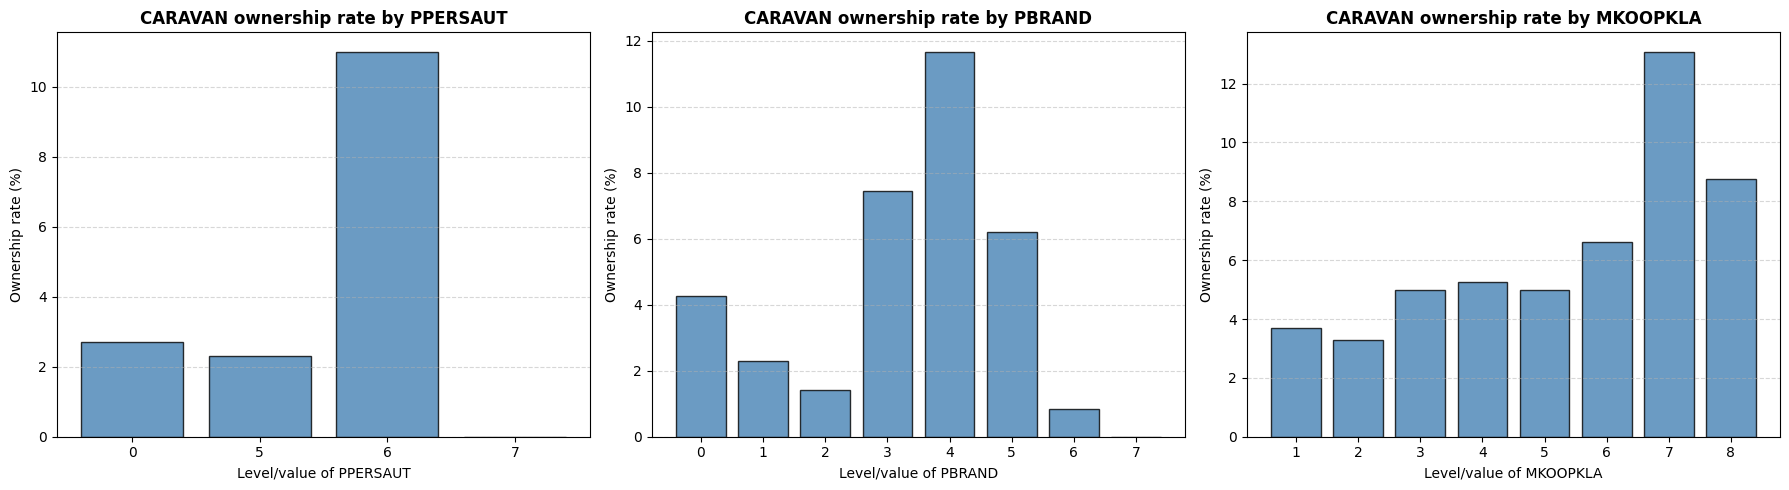

In [9]:
# 3. Plot bar charts for the three most important features to visualize trends
# Select three notable features: PPERSAUT (car insurance), PBRAND (fire insurance), and MKOOPKLA (purchasing power)
top_features_to_plot = ['PPERSAUT', 'PBRAND', 'MKOOPKLA']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(top_features_to_plot):
    # Calculate the observed insurance ownership rate for each segment
    grouped = y.groupby(X[col]).mean() * 100
    counts = X[col].value_counts().sort_index()

    # Plot only groups with a sufficient number of observations (>= 5)
    valid_idx = counts[counts >= 5].index
    grouped = grouped.loc[valid_idx]

    axes[i].bar(grouped.index.astype(str), grouped.values, color='steelblue', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'CARAVAN ownership rate by {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(f'Level/value of {col}')
    axes[i].set_ylabel('Ownership rate (%)')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 3.3 Identifying Redundant Predictors



In [10]:
import pandas as pd

# Find features where a value in one feature uniquely determines the value in another feature
redundant_pairs = []
features_to_check = X.columns

for col_a in features_to_check:
    for col_b in features_to_check:
        if col_a != col_b:
            # Group by col_a and check if each group has exactly 1 unique value of col_b
            unique_b_per_a = X.groupby(col_a)[col_b].nunique()
            if (unique_b_per_a <= 1).all():
                redundant_pairs.append((col_a, col_b))

# Extract the parent/determining features (feature_a) into a list
determining_features = list(set([pair[0] for pair in redundant_pairs]))

print(f"Found {len(redundant_pairs)} perfect dependency pairs.")
for pair in redundant_pairs[:10]:
    print(f" - {pair[0]} uniquely determines {pair[1]}")
if len(redundant_pairs) > 10:
    print("   ...")

print("\nList of determining features to handle later:", determining_features)

Found 10 perfect dependency pairs.
 - MOSTYPE uniquely determines MOSHOOFD
 - PWALAND uniquely determines AWALAND
 - PVRAAUT uniquely determines AVRAAUT
 - PPERSONG uniquely determines APERSONG
 - PGEZONG uniquely determines AGEZONG
 - PZEILPL uniquely determines AZEILPL
 - PINBOED uniquely determines AINBOED
 - AVRAAUT uniquely determines PVRAAUT
 - AZEILPL uniquely determines PZEILPL
 - AFIETS uniquely determines PFIETS

List of determining features to handle later: ['AFIETS', 'AZEILPL', 'AVRAAUT', 'PVRAAUT', 'PWALAND', 'PGEZONG', 'PPERSONG', 'PZEILPL', 'PINBOED', 'MOSTYPE']


### 3.4 Translating EDA Findings into Modelling Decisions

The exploratory data analysis (EDA) leads to the following decisions for the modelling pipeline.

1. **Treatment of significant but non-monotonic predictors (`non_monotonic_features`)**
   - We identify **17 statistically significant predictors** (including `PWAPART`, `PPERSAUT`, `PBRAND`, and `MINKGEM`) whose relationships with `CARAVAN` do not follow a clearly monotonic pattern.
   - **Modelling implication:** Linear and logistic models may not capture these relationships adequately without additional transformations. We therefore consider approaches such as binning, one-hot encoding, or spline transformations. Tree-based models (Decision Tree and Random Forest in this notebook) can represent non-monotonic relationships through their split structure without requiring the same manual transformations.

2. **Treatment of redundant and perfectly dependent predictors (`determining_features`)**
   - The analysis identifies **10 pairs of perfectly dependent predictors**, where the values of one variable uniquely determine the values of another. For example, `MOSTYPE` determines `MOSHOOFD` (customer subtype versus main type), while product-premium variables (e.g. `PVRAAUT`) correspond perfectly to product-policy-count variables (e.g. `AVRAAUT`).
   - **Modelling implication:** To reduce redundancy and avoid severe multicollinearity in linear models, we remove one variable from each perfectly dependent pair before model fitting. Where appropriate, we retain the policy-count variables (`A…`) or the more detailed variable (for example, `MOSTYPE` rather than `MOSHOOFD`) and exclude the corresponding redundant variable.



## 4. Feature Selection and Engineering



### 4.1 Removing Redundant Predictors



In [11]:
# Derive candidate redundant columns from the dependency analysis rather than hard-coding a stale list.
# Keep one representative per exact-dependency group by dropping the dependent column when possible.
redundant_to_drop = []
for parent, child in redundant_pairs:
    # Skip a pair if either column is already dropped, so a mutual pair
    # (A determines B and B determines A) loses only one of its two members.
    if parent in redundant_to_drop or child in redundant_to_drop:
        continue
    redundant_to_drop.append(child)
redundant_to_drop = sorted(redundant_to_drop)
# Do not remove nominal feature MOSTYPE just because of cardinality; only exact dependency candidates are considered.
print(f"Candidate exact-dependency columns to drop: {redundant_to_drop}")

for frame in (X_dev_raw, X_val_raw, X_full_train, X_test):
    frame.drop(columns=redundant_to_drop, inplace=True, errors="ignore")
X = X_dev_raw
print(f"Dropped {len(redundant_to_drop)} data-derived redundant columns.")
print(f"New development shape: {X_dev_raw.shape}")


Candidate exact-dependency columns to drop: ['AGEZONG', 'AINBOED', 'APERSONG', 'AVRAAUT', 'AWALAND', 'AZEILPL', 'MOSHOOFD', 'PFIETS']
Dropped 8 data-derived redundant columns.
New development shape: (4657, 77)


### 4.2 One-Hot Encoding Selected Predictors



In [12]:
# We will prepare for one-hot encoding on non-monotonic features
# Since we modified the original dataframes in-place, we check presence in X_dev_raw

features_to_encode = []
for col in non_monotonic_features:
    if col in X_dev_raw.columns:
        features_to_encode.append(col)

print(f"Features to be One-Hot Encoded (present in X_dev_raw): {len(features_to_encode)}")
print(features_to_encode)

Features to be One-Hot Encoded (present in X_dev_raw): 17
['MOPLHOOG', 'MBERHOOG', 'MBERARBG', 'MSKA', 'MSKC', 'MINK4575', 'MINK7512', 'MINKGEM', 'PWAPART', 'PPERSAUT', 'PMOTSCO', 'PBRAND', 'PPLEZIER', 'PBYSTAND', 'AWAPART', 'APERSAUT', 'ABRAND']


In [13]:
# Calculate and display the number of unique categories ONLY for the filtered features to encode using updated X_dev_raw
encoded_uniques = X_dev_raw[features_to_encode].nunique().sort_values(ascending=False)

# Create a DataFrame for nice visualization
unique_counts_df = pd.DataFrame({
    'Feature': encoded_uniques.index,
    'Unique_Values_Count': encoded_uniques.values
})

display(unique_counts_df)

,Feature,Unique_Values_Count
0,MOPLHOOG,10
1,MBERHOOG,10
2,MBERARBG,10
3,MSKA,10
4,MSKC,10
5,MINK4575,10
6,MINK7512,10
7,MINKGEM,10
8,PBRAND,9
9,APERSAUT,7


In [14]:
import numpy as np
import pandas as pd

def calculate_iv(df, target, eps=1e-4):
    iv_dict = {}
    target_pos = target.sum()
    target_neg = len(target) - target_pos

    for col in df.columns:
        # Create a frequency cross-tabulation
        ct = pd.crosstab(df[col], target)

        # Get frequencies for class 0 and class 1
        n_0 = ct[0] if 0 in ct.columns else pd.Series(0, index=ct.index)
        n_1 = ct[1] if 1 in ct.columns else pd.Series(0, index=ct.index)

        # Calculate the percentage distribution
        p_0 = (n_0 + eps) / (target_neg + eps * len(ct))
        p_1 = (n_1 + eps) / (target_pos + eps * len(ct))

        # Calculate Weight of Evidence (WOE) and Information Value (IV) for each feature level
        woe = np.log(p_1 / p_0)
        iv_values = (p_1 - p_0) * woe

        # Total IV for the feature
        iv_dict[col] = iv_values.sum()

    return pd.Series(iv_dict)

# Calculate IV on the development set X_dev_raw
iv_scores = calculate_iv(X_dev_raw, y_dev)

# Create a display DataFrame and rank the features
iv_df = pd.DataFrame({
    'Feature': iv_scores.index,
    'Information_Value': iv_scores.values
}).sort_values(by='Information_Value', ascending=False).reset_index(drop=True)

# Add importance categories based on standard IV thresholds:
# < 0.02: Useless; 0.02 to 0.1: Weak; 0.1 to 0.3: Medium; 0.3 to 0.5: Strong; > 0.5: Suspiciously High
def classify_iv(val):
    if val < 0.02: return 'Useless/No predictive power'
    elif val < 0.1: return 'Weak predictor'
    elif val < 0.3: return 'Medium predictor'
    elif val < 0.5: return 'Strong predictor'
    else: return 'Suspiciously high predictor'

iv_df['Predictive_Power'] = iv_df['Information_Value'].apply(classify_iv)

# Display the most important features
display(iv_df.head(30))

,Feature,Information_Value,Predictive_Power
0,PPERSAUT,0.619094,Suspiciously high predictor
1,MOSTYPE,0.599992,Suspiciously high predictor
2,APERSAUT,0.411442,Strong predictor
3,PBRAND,0.407759,Strong predictor
4,MINKM30,0.356481,Strong predictor
5,MINKGEM,0.307304,Strong predictor
6,MBERBOER,0.248139,Medium predictor
7,MGODRK,0.223500,Medium predictor
8,MAUT0,0.205666,Medium predictor
9,MSKA,0.205616,Medium predictor


In [15]:
# Filter the IV ranking to retain only features selected for one-hot encoding (features_to_encode)
iv_onehot_df = iv_df[iv_df['Feature'].isin(features_to_encode)].copy()

# Add the number of unique values to the table
unique_counts = X_dev_raw[features_to_encode].nunique().to_frame(name='Unique_Values_Count')
iv_onehot_df = iv_onehot_df.merge(unique_counts, left_on='Feature', right_index=True)

# Reorder columns for readability: feature name -> number of levels -> IV -> predictive strength
iv_onehot_df = iv_onehot_df[['Feature', 'Unique_Values_Count', 'Information_Value', 'Predictive_Power']].reset_index(drop=True)

print(f"IV ranking with the number of levels for {len(iv_onehot_df)} features considered for one-hot encoding:")
display(iv_onehot_df)

IV ranking with the number of levels for 17 features considered for one-hot encoding:


,Feature,Unique_Values_Count,Information_Value,Predictive_Power
0,PPERSAUT,5,0.619094,Suspiciously high predictor
1,APERSAUT,7,0.411442,Strong predictor
2,PBRAND,9,0.407759,Strong predictor
3,MINKGEM,10,0.307304,Strong predictor
4,MSKA,10,0.205616,Medium predictor
5,PWAPART,4,0.144292,Medium predictor
6,MINK4575,10,0.136721,Medium predictor
7,AWAPART,3,0.130640,Medium predictor
8,MOPLHOOG,10,0.124489,Medium predictor
9,PPLEZIER,7,0.113875,Medium predictor


In [16]:
from sklearn.preprocessing import OneHotEncoder
import pandas as pd

# 1. Select the five features with the highest IV from iv_onehot_df
top_5_onehot_features = list(iv_onehot_df['Feature'].head(5))
# MOSTYPE is nominal with 41 levels. It is one-hot encoded regardless of its IV rank,
# so that linear models and the SVM do not impose an order on its codes.
onehot_features = top_5_onehot_features + ["MOSTYPE"]
print("Features selected for one-hot encoding (top-5 by IV + nominal MOSTYPE):", onehot_features)

# 2. Initialize OneHotEncoder (handle_unknown='ignore' handles unseen levels in validation/test, if any)
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore', dtype=int)

# 3. Fit the encoder on the development training set X_dev_raw for the five selected features
encoder.fit(X_dev_raw[onehot_features])

# 4. Define a function to encode selected features and concatenate unchanged columns
def apply_onehot_encoder(df, encoder, features_to_encode):
    # Apply one-hot encoding
    encoded_array = encoder.transform(df[features_to_encode])

    # Get the new column names after one-hot encoding
    encoded_col_names = encoder.get_feature_names_out(features_to_encode)

    # Create a DataFrame from the encoded columns
    df_encoded = pd.DataFrame(encoded_array, columns=encoded_col_names, index=df.index)

    # Get the columns that are not encoded
    remaining_cols = df.drop(columns=features_to_encode)

    # Concatenate both parts
    df_result = pd.concat([df_encoded, remaining_cols], axis=1)
    return df_result

# 5. Create the corresponding transformed DataFrames
X_1h_dev_raw = apply_onehot_encoder(X_dev_raw, encoder, onehot_features)
X_1h_val_raw = apply_onehot_encoder(X_val_raw, encoder, onehot_features)
X_1h_test_raw = apply_onehot_encoder(X_test, encoder, onehot_features)

# Print the transformed DataFrame shapes for verification
print(f"\nShapes after applying one-hot encoding:")
print(f" - X_1h_dev_raw: {X_1h_dev_raw.shape} (Original: {X_dev_raw.shape})")
print(f" - X_1h_val_raw: {X_1h_val_raw.shape} (Original: {X_val_raw.shape})")
print(f" - X_1h_test_raw: {X_1h_test_raw.shape} (Original: {X_test.shape})")

# Preview the first few rows of the transformed development set
display(X_1h_dev_raw.head())


Features selected for one-hot encoding (top-5 by IV + nominal MOSTYPE): ['PPERSAUT', 'APERSAUT', 'PBRAND', 'MINKGEM', 'MSKA', 'MOSTYPE']

Shapes after applying one-hot encoding:
 - X_1h_dev_raw: (4657, 152) (Original: (4657, 77))
 - X_1h_val_raw: (1165, 152) (Original: (1165, 77))
 - X_1h_test_raw: (4000, 152) (Original: (4000, 77))


,PPERSAUT_0,PPERSAUT_5,PPERSAUT_6,PPERSAUT_7,PPERSAUT_8,APERSAUT_0,APERSAUT_1,APERSAUT_2,APERSAUT_3,APERSAUT_4,APERSAUT_6,APERSAUT_7,PBRAND_0,PBRAND_1,PBRAND_2,...,PBYSTAND,AWAPART,AWABEDR,ABESAUT,AMOTSCO,AAANHANG,ATRACTOR,AWERKT,ABROM,ALEVEN,AWAOREG,ABRAND,APLEZIER,AFIETS,ABYSTAND
198,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
676,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
330,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1231,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
5545,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0


## 5. Model Training and Hyperparameter Tuning



### 5.1 Logistic Regression



In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score
import pandas as pd

def evaluate_logistic_regression(X_train, y_train, X_val, y_val, C=1.0, penalty='l2', solver='lbfgs', class_weight='balanced', random_state=42):
    """
    Train a Logistic Regression model and evaluate it using the main metrics.

    Parameters:
    ----------
    X_train, y_train : pandas.DataFrame / Series
        Features and labels used for training.
    X_val, y_val : pandas.DataFrame / Series
        Features and labels used for validation.
    C : float, default=1.0
        Inverse regularization strength.
    penalty : str, default='l2'
        Regularization penalty ('l1', 'l2', or 'elasticnet').
    solver : str, default='lbfgs'
        Optimization algorithm ('lbfgs', 'liblinear', 'saga', ...).
    class_weight : str or dict, default='balanced'
        Class weights (useful for imbalanced datasets such as CARAVAN).
    random_state : int, default=42
        Random seed for reproducibility.

    Returns:
    ------
    model : LogisticRegression
        The fitted model.
    metrics : dict
        Evaluation metrics, including Average Precision, ROC AUC, and F1-score on both training and validation sets.
    """
    # 1. Initialize and train the model (increase max_iter to 5000 to avoid ConvergenceWarning)
    model = LogisticRegression(
        C=C,
        penalty=penalty,
        solver=solver,
        class_weight=class_weight,
        max_iter=5000,
        random_state=random_state
    )
    model.fit(X_train, y_train)

    # 2. Predict probabilities and class labels
    # Training set
    y_train_pred_proba = model.predict_proba(X_train)[:, 1]
    y_train_pred = model.predict(X_train)

    # Validation set
    y_val_pred_proba = model.predict_proba(X_val)[:, 1]
    y_val_pred = model.predict(X_val)

    # 3. Calculate evaluation metrics
    metrics = {
        'train_ap': average_precision_score(y_train, y_train_pred_proba),
        'train_auc': roc_auc_score(y_train, y_train_pred_proba),
        'train_f1': f1_score(y_train, y_train_pred),
        'val_ap': average_precision_score(y_val, y_val_pred_proba),
        'val_auc': roc_auc_score(y_val, y_val_pred_proba),
        'val_f1': f1_score(y_val, y_val_pred)
    }

    return model, metrics

# Evaluate a baseline model using the one-hot encoded dataset created above
baseline_model, baseline_metrics = evaluate_logistic_regression(
    X_train=X_1h_dev_raw,
    y_train=y_dev,
    X_val=X_1h_val_raw,
    y_val=y_val,
    C=1.0,
    class_weight='balanced'
)

# Display the results
print("--- Baseline Logistic Regression Evaluation (Convergence Optimized) ---")
for metric_name, score in baseline_metrics.items():
    print(f"{metric_name:10s}: {score:.4f}")

--- Baseline Logistic Regression Evaluation (Convergence Optimized) ---
train_ap  : 0.2223
train_auc : 0.8379
train_f1  : 0.2640
val_ap    : 0.2002
val_auc   : 0.7471
val_f1    : 0.2157


In [18]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on the development training set and transform all datasets
# Use the one-hot encoded data (X_1h_...)
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_1h_dev_raw), columns=X_1h_dev_raw.columns, index=X_1h_dev_raw.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_1h_val_raw), columns=X_1h_val_raw.columns, index=X_1h_val_raw.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_1h_test_raw), columns=X_1h_test_raw.columns, index=X_1h_test_raw.index)

print("Successfully standardized the data for Logistic Regression!")
print(f"Scaled training data shape: {X_train_scaled.shape}")

Successfully standardized the data for Logistic Regression!
Scaled training data shape: (4657, 152)


In [19]:
import itertools
import pandas as pd

# Define a compact parameter grid focused on the necessary parameters
C_values = [0.01, 0.1, 1.0, 10.0]
penalties = ['l1', 'l2']

tuning_results = []

# Iterate over combinations of C and penalty values
for C, penalty in itertools.product(C_values, penalties):
    # Use the 'liblinear' solver, which supports both l1 and l2 penalties
    solver = 'liblinear'

    _, metrics = evaluate_logistic_regression(
        X_train=X_train_scaled,
        y_train=y_dev,
        X_val=X_val_scaled,
        y_val=y_val,
        C=C,
        penalty=penalty,
        solver=solver,
        class_weight='balanced',
        random_state=42
    )

    tuning_results.append({
        'C': C,
        'penalty': penalty,
        'train_ap': metrics['train_ap'],
        'val_ap': metrics['val_ap'],
        'val_auc': metrics['val_auc'],
        'val_f1': metrics['val_f1']
    })

# Create a results DataFrame sorted by the primary metric, validation AP
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values(by='val_ap', ascending=False).reset_index(drop=True)

print("--- Logistic Regression Tuning Results on Scaled Data ---")
display(tuning_df)

--- Logistic Regression Tuning Results on Scaled Data ---


,C,penalty,train_ap,val_ap,val_auc,val_f1
0,0.01,l1,0.216043,0.276905,0.824534,0.236786
1,0.01,l2,0.233907,0.203764,0.773405,0.221198
2,10.00,l1,0.228332,0.201599,0.740476,0.213592
3,1.00,l1,0.228330,0.201360,0.740280,0.210024
4,10.00,l2,0.228417,0.201027,0.738845,0.214112
5,1.00,l2,0.228193,0.200959,0.738284,0.212048
6,0.10,l2,0.228659,0.200529,0.748943,0.207229
7,0.10,l1,0.232074,0.198611,0.772179,0.220657


### 5.2 K-Nearest Neighbours (KNN)



In [20]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# 1. Initialize MinMaxScaler to scale data to the [0, 1] range
min_max_scaler = MinMaxScaler()

# Fit and transform the one-hot encoded data to retain the available information
X_train_knn = pd.DataFrame(min_max_scaler.fit_transform(X_1h_dev_raw), columns=X_1h_dev_raw.columns, index=X_1h_dev_raw.index)
X_val_knn = pd.DataFrame(min_max_scaler.transform(X_1h_val_raw), columns=X_1h_val_raw.columns, index=X_1h_val_raw.index)
X_test_knn = pd.DataFrame(min_max_scaler.transform(X_1h_test_raw), columns=X_1h_test_raw.columns, index=X_1h_test_raw.index)

print("Successfully scaled the data to [0, 1] for KNN!")
print(f"KNN training set shape: {X_train_knn.shape}")

Successfully scaled the data to [0, 1] for KNN!
KNN training set shape: (4657, 152)


In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def evaluate_knn(X_train, y_train, X_val, y_val, n_neighbors=5, weights='uniform', metric='minkowski'):
    """
    Train and evaluate a KNN model with configurable distance metrics.
    """
    # Initialize the model and use all available CPU cores
    model = KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, metric=metric, n_jobs=-1)
    model.fit(X_train, y_train)

    # Predict probabilities for the positive class (1)
    y_train_pred_proba = model.predict_proba(X_train)[:, 1]
    y_train_pred = model.predict(X_train)

    y_val_pred_proba = model.predict_proba(X_val)[:, 1]
    y_val_pred = model.predict(X_val)

    # Calculate the metrics
    metrics = {
        'train_ap': average_precision_score(y_train, y_train_pred_proba),
        'train_auc': roc_auc_score(y_train, y_train_pred_proba),
        'train_f1': f1_score(y_train, y_train_pred),
        'val_ap': average_precision_score(y_val, y_val_pred_proba),
        'val_auc': roc_auc_score(y_val, y_val_pred_proba),
        'val_f1': f1_score(y_val, y_val_pred)
    }
    return model, metrics

In [22]:
import itertools
import pandas as pd

# Define an expanded parameter grid for KNN tuning
neighbor_options = [3, 5, 7, 9, 11, 13, 15]
weight_options = ['uniform', 'distance']
metric_options = ['euclidean', 'manhattan'] # Try two commonly used distance metrics

knn_tuning_results = []

# Search the expanded parameter grid
for n_neighbors, weights, metric in itertools.product(neighbor_options, weight_options, metric_options):
    _, metrics = evaluate_knn(
        X_train=X_train_knn,
        y_train=y_dev,
        X_val=X_val_knn,
        y_val=y_val,
        n_neighbors=n_neighbors,
        weights=weights,
        metric=metric
    )

    knn_tuning_results.append({
        'n_neighbors': n_neighbors,
        'weights': weights,
        'metric': metric,
        'train_ap': metrics['train_ap'],
        'val_ap': metrics['val_ap'],
        'val_auc': metrics['val_auc'],
        'val_f1': metrics['val_f1']
    })

# Display results sorted by validation AP
knn_tuning_df = pd.DataFrame(knn_tuning_results)
knn_tuning_df = knn_tuning_df.sort_values(by='val_ap', ascending=False).reset_index(drop=True)

print("--- Expanded KNN Tuning Results (Sorted by Validation AP) ---")
display(knn_tuning_df.head(15))

--- Expanded KNN Tuning Results (Sorted by Validation AP) ---


,n_neighbors,weights,metric,train_ap,val_ap,val_auc,val_f1
0,15,uniform,manhattan,0.227882,0.161290,0.714044,0.000000
1,13,uniform,manhattan,0.232232,0.142544,0.703699,0.000000
2,13,uniform,euclidean,0.261127,0.141752,0.664703,0.028169
3,15,uniform,euclidean,0.244083,0.140344,0.673712,0.000000
4,11,uniform,euclidean,0.262552,0.131944,0.669485,0.028169
5,15,distance,euclidean,0.992325,0.129718,0.667854,0.050633
6,13,distance,euclidean,0.992327,0.128857,0.660431,0.050633
7,11,uniform,manhattan,0.248024,0.128584,0.682074,0.000000
8,15,distance,manhattan,0.988251,0.122354,0.684814,0.049383
9,11,distance,euclidean,0.992327,0.120776,0.668376,0.050633


### 5.3 Decision Tree



In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def evaluate_decision_tree(X_train, y_train, X_val, y_val, criterion='gini', max_depth=None, class_weight='balanced', random_state=42):
    """
    Train and evaluate a Decision Tree model.
    """
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=max_depth,
        class_weight=class_weight,
        random_state=random_state
    )
    model.fit(X_train, y_train)

    # Predict probabilities and class labels
    y_train_pred_proba = model.predict_proba(X_train)[:, 1]
    y_train_pred = model.predict(X_train)

    y_val_pred_proba = model.predict_proba(X_val)[:, 1]
    y_val_pred = model.predict(X_val)

    # Calculate performance metrics
    metrics = {
        'train_ap': average_precision_score(y_train, y_train_pred_proba),
        'train_auc': roc_auc_score(y_train, y_train_pred_proba),
        'train_f1': f1_score(y_train, y_train_pred),
        'val_ap': average_precision_score(y_val, y_val_pred_proba),
        'val_auc': roc_auc_score(y_val, y_val_pred_proba),
        'val_f1': f1_score(y_val, y_val_pred)
    }
    return model, metrics

In [24]:
import itertools
import pandas as pd

# Define the Decision Tree tuning parameter grid
# With over 100 one-hot encoded features, excessive tree depth may cause substantial overfitting.
# The depth values [3, 5, 8, 12, 15] provide a reasonable range to explore.
criterion_options = ['gini', 'entropy']
max_depth_options = [3, 5, 8, 12, 15, 20, 25, None] # None allows the decision tree to grow without a specified maximum depth

dt_tuning_results = []

# Search all parameter combinations
for criterion, max_depth in itertools.product(criterion_options, max_depth_options):
    # Use the original one-hot encoded data (decision trees are not sensitive to feature scaling)
    _, metrics = evaluate_decision_tree(
        X_train=X_1h_dev_raw,
        y_train=y_dev,
        X_val=X_1h_val_raw,
        y_val=y_val,
        criterion=criterion,
        max_depth=max_depth,
        class_weight='balanced',
        random_state=42
    )

    dt_tuning_results.append({
        'criterion': criterion,
        'max_depth': 'Unlimited' if max_depth is None else max_depth,
        'train_ap': metrics['train_ap'],
        'val_ap': metrics['val_ap'],
        'val_auc': metrics['val_auc'],
        'val_f1': metrics['val_f1']
    })

# Display the ranked results
dt_tuning_df = pd.DataFrame(dt_tuning_results)
dt_tuning_df = dt_tuning_df.sort_values(by='val_ap', ascending=False).reset_index(drop=True)

print("--- Decision Tree Tuning Results (Sorted by Validation AP) ---")
display(dt_tuning_df)

--- Decision Tree Tuning Results (Sorted by Validation AP) ---


,criterion,max_depth,train_ap,val_ap,val_auc,val_f1
0,entropy,3,0.156849,0.169971,0.770052,0.216319
1,entropy,5,0.216005,0.165516,0.705793,0.287823
2,gini,5,0.201461,0.158782,0.735199,0.224719
3,gini,3,0.139895,0.143930,0.760939,0.209924
4,entropy,8,0.346638,0.132752,0.631129,0.170213
5,gini,8,0.310166,0.129285,0.631174,0.177106
6,gini,12,0.497772,0.102208,0.604064,0.174419
7,entropy,12,0.585468,0.099086,0.594175,0.143210
8,entropy,15,0.716886,0.091963,0.584462,0.157377
9,gini,15,0.610655,0.084501,0.574083,0.155477


### 5.4 Random Forest



In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def evaluate_random_forest(X_train, y_train, X_val, y_val, n_estimators=100, max_depth=None, max_features='sqrt', class_weight='balanced', random_state=42):
    """
    Train and evaluate a Random Forest model.
    """
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        max_features=max_features,
        class_weight=class_weight,
        n_jobs=-1,
        random_state=random_state
    )
    model.fit(X_train, y_train)

    # Predict positive-class probabilities and labels
    y_train_pred_proba = model.predict_proba(X_train)[:, 1]
    y_train_pred = model.predict(X_train)

    y_val_pred_proba = model.predict_proba(X_val)[:, 1]
    y_val_pred = model.predict(X_val)

    # Calculate performance metrics
    metrics = {
        'train_ap': average_precision_score(y_train, y_train_pred_proba),
        'train_auc': roc_auc_score(y_train, y_train_pred_proba),
        'train_f1': f1_score(y_train, y_train_pred),
        'val_ap': average_precision_score(y_val, y_val_pred_proba),
        'val_auc': roc_auc_score(y_val, y_val_pred_proba),
        'val_f1': f1_score(y_val, y_val_pred)
    }
    return model, metrics

In [26]:
import itertools
import pandas as pd

# Define the Random Forest tuning parameter grid
n_estimators_options = [100, 200]
max_depth_options = [5, 10, 15, None]  # Limit tree depth to help control overfitting
max_features_options = ['sqrt', 'log2']

rf_tuning_results = []

# Search the full parameter grid
for n_estimators, max_depth, max_features in itertools.product(n_estimators_options, max_depth_options, max_features_options):
    # Use the original training data because Random Forest is not sensitive to feature scaling
    _, metrics = evaluate_random_forest(
        X_train=X_1h_dev_raw,
        y_train=y_dev,
        X_val=X_1h_val_raw,
        y_val=y_val,
        n_estimators=n_estimators,
        max_depth=max_depth,
        max_features=max_features,
        class_weight='balanced',
        random_state=42
    )

    rf_tuning_results.append({
        'n_estimators': n_estimators,
        'max_depth': 'Unlimited' if max_depth is None else max_depth,
        'max_features': max_features,
        'train_ap': metrics['train_ap'],
        'val_ap': metrics['val_ap'],
        'val_auc': metrics['val_auc'],
        'val_f1': metrics['val_f1']
    })

# Display results sorted by descending validation AP
rf_tuning_df = pd.DataFrame(rf_tuning_results)
rf_tuning_df = rf_tuning_df.sort_values(by='val_ap', ascending=False).reset_index(drop=True)

print("--- Random Forest Tuning Results (Sorted by Validation AP) ---")
display(rf_tuning_df.head(15))

--- Random Forest Tuning Results (Sorted by Validation AP) ---


,n_estimators,max_depth,max_features,train_ap,val_ap,val_auc,val_f1
0,100,5,sqrt,0.308058,0.244044,0.805173,0.254335
1,200,5,sqrt,0.301282,0.236953,0.803673,0.264368
2,200,5,log2,0.311563,0.208811,0.803803,0.276276
3,100,5,log2,0.320619,0.205543,0.795910,0.267477
4,100,10,sqrt,0.641425,0.190613,0.787260,0.257669
5,200,10,log2,0.627678,0.184140,0.774410,0.254545
6,100,10,log2,0.624342,0.183477,0.768748,0.265060
7,200,10,sqrt,0.649749,0.182544,0.779002,0.271605
8,100,15,log2,0.863145,0.168255,0.767130,0.145455
9,100,15,sqrt,0.849491,0.167403,0.753868,0.172414


### 5.5 Support Vector Machine (SVM)



In [27]:
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score

def evaluate_svm(X_train, y_train, X_val, y_val, C=1.0, kernel='rbf', class_weight='balanced', random_state=42):
    """
    Train and evaluate a Support Vector Machine (SVM) model.
    """
    # Initialize SVC with probability=True to obtain probabilities for AP and AUC calculations
    model = SVC(
        C=C,
        kernel=kernel,
        class_weight=class_weight,
        probability=True,
        random_state=random_state
    )
    model.fit(X_train, y_train)

    # Predict positive-class probabilities and labels
    y_train_pred_proba = model.predict_proba(X_train)[:, 1]
    y_train_pred = model.predict(X_train)

    y_val_pred_proba = model.predict_proba(X_val)[:, 1]
    y_val_pred = model.predict(X_val)

    # Calculate the metrics
    metrics = {
        'train_ap': average_precision_score(y_train, y_train_pred_proba),
        'train_auc': roc_auc_score(y_train, y_train_pred_proba),
        'train_f1': f1_score(y_train, y_train_pred),
        'val_ap': average_precision_score(y_val, y_val_pred_proba),
        'val_auc': roc_auc_score(y_val, y_val_pred_proba),
        'val_f1': f1_score(y_val, y_val_pred)
    }
    return model, metrics

In [28]:
import itertools
import pandas as pd

# Define the SVM parameter grid
C_options = [0.01, 0.1, 1.0, 10.0]
kernel_options = ['linear', 'rbf']

svm_tuning_results = []

print("Searching for the best SVM parameters (please wait)...\n")

# Search the parameter grid
for C, kernel in itertools.product(C_options, kernel_options):
    _, metrics = evaluate_svm(
        X_train=X_train_scaled,
        y_train=y_dev,
        X_val=X_val_scaled,
        y_val=y_val,
        C=C,
        kernel=kernel,
        class_weight='balanced',
        random_state=42
    )

    svm_tuning_results.append({
        'C': C,
        'kernel': kernel,
        'train_ap': metrics['train_ap'],
        'val_ap': metrics['val_ap'],
        'val_auc': metrics['val_auc'],
        'val_f1': metrics['val_f1']
    })

# Sort results by descending validation AP
svm_tuning_df = pd.DataFrame(svm_tuning_results)
svm_tuning_df = svm_tuning_df.sort_values(by='val_ap', ascending=False).reset_index(drop=True)

print("--- SVM Tuning Results on Scaled Data (Sorted by Validation AP) ---")
display(svm_tuning_df)

Searching for the best SVM parameters (please wait)...

--- SVM Tuning Results on Scaled Data (Sorted by Validation AP) ---


,C,kernel,train_ap,val_ap,val_auc,val_f1
0,0.01,rbf,0.218830,0.215798,0.786491,0.213280
1,0.10,rbf,0.307900,0.195956,0.783464,0.235897
2,0.01,linear,0.205550,0.192768,0.759224,0.219178
3,10.00,linear,0.201331,0.187786,0.724560,0.208145
4,1.00,linear,0.202279,0.176908,0.723594,0.204545
5,0.10,linear,0.204383,0.174466,0.730326,0.210046
6,1.00,rbf,0.587166,0.116732,0.693757,0.215385
7,10.00,rbf,0.862557,0.097768,0.645890,0.136986


## 6. Model Evaluation and Comparison

All model comparisons in this section are based on validation-set performance. The official test set is not used for model selection.



In [29]:
import pandas as pd
import numpy as np

# Compare top configurations using validation only. The official test set is reserved for the final locked evaluation.
tuning_tables = {
    "Logistic Regression": tuning_df,
    "KNN": knn_tuning_df,
    "Decision Tree": dt_tuning_df,
    "Random Forest": rf_tuning_df,
    "SVM": svm_tuning_df,
}
comparison_rows = []
for family, table in tuning_tables.items():
    for rank, (_, row) in enumerate(table.head(3).iterrows(), start=1):
        params = {k: row[k] for k in table.columns
                  if k not in {"train_ap", "train_auc", "train_f1", "val_ap", "val_auc", "val_f1"}}
        comparison_rows.append({
            "Model_Family": family, "Rank_by_Val_AP": rank,
            "Config": ", ".join(f"{k}={v}" for k, v in params.items()),
            "Train_AP": row.get("train_ap", np.nan),
            "Val_AP": row["val_ap"], "Val_AUC": row["val_auc"],
            "Val_F1": row.get("val_f1", np.nan)
        })
comparison_df = pd.DataFrame(comparison_rows).sort_values(
    ["Model_Family", "Rank_by_Val_AP"]
).reset_index(drop=True)

print("Top tuning configurations per model family (ranked on validation AP; no test scores used):")
display(comparison_df.round(4))


Top tuning configurations per model family (ranked on validation AP; no test scores used):


,Model_Family,Rank_by_Val_AP,Config,Train_AP,Val_AP,Val_AUC,Val_F1
0,Decision Tree,1,"criterion=entropy, max_depth=3",0.1568,0.1700,0.7701,0.2163
1,Decision Tree,2,"criterion=entropy, max_depth=5",0.2160,0.1655,0.7058,0.2878
2,Decision Tree,3,"criterion=gini, max_depth=5",0.2015,0.1588,0.7352,0.2247
3,KNN,1,"n_neighbors=15, weights=uniform, metric=manhattan",0.2279,0.1613,0.7140,0.0000
4,KNN,2,"n_neighbors=13, weights=uniform, metric=manhattan",0.2322,0.1425,0.7037,0.0000
5,KNN,3,"n_neighbors=13, weights=uniform, metric=euclidean",0.2611,0.1418,0.6647,0.0282
6,Logistic Regression,1,"C=0.01, penalty=l1",0.2160,0.2769,0.8245,0.2368
7,Logistic Regression,2,"C=0.01, penalty=l2",0.2339,0.2038,0.7734,0.2212
8,Logistic Regression,3,"C=10.0, penalty=l1",0.2283,0.2016,0.7405,0.2136
9,Random Forest,1,"n_estimators=100, max_depth=5, max_features=sqrt",0.3081,0.2440,0.8052,0.2543


### 6.1 Validation-Based Feature Engineering Experiments



In [30]:
import pandas as pd
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score

# 1. Identify statistically significant features from the chi-square tests
sig_features = [feature for feature in significant_features if feature in X_dev_raw.columns]

# Retrieve the previously calculated IV scores for these features from iv_df
sig_iv_df = iv_df[iv_df['Feature'].isin(sig_features)].copy()

# 2. Use percentiles to split the remaining features into three groups of approximately equal size
iv_values = sig_iv_df['Information_Value'].values
threshold_low = np.percentile(iv_values, 33.33)  # First tertile
threshold_high = np.percentile(iv_values, 66.67) # Second tertile

# Group features using these data-driven thresholds to balance group sizes
group_1_cols = sig_iv_df[sig_iv_df['Information_Value'] >= threshold_high]['Feature'].tolist()             # Group 1 (High)
group_2_cols = sig_iv_df[(sig_iv_df['Information_Value'] >= threshold_low) & (sig_iv_df['Information_Value'] < threshold_high)]['Feature'].tolist() # Group 2 (Medium)
group_3_cols = sig_iv_df[sig_iv_df['Information_Value'] < threshold_low]['Feature'].tolist()              # Group 3 (Low)

print("=== FEATURE GROUPING BASED ON ADAPTIVE INFORMATION VALUE (IV) THRESHOLDS ===")
print(f"Lower split threshold (33.33%): {threshold_low:.4f}")
print(f"Upper split threshold (66.67%): {threshold_high:.4f}")
print(f"- Group 1 (High association): {len(group_1_cols)} features")
print(f"- Group 2 (Moderate association): {len(group_2_cols)} features")
print(f"- Group 3 (Low association): {len(group_3_cols)} features")
print(f"Total number of grouped features: {len(group_1_cols) + len(group_2_cols) + len(group_3_cols)} / {len(sig_iv_df)}")

# Derive best configurations from the tuning tables instead of hard-coding them.
best_configs = {
    "Logistic Regression": {"C": tuning_df.iloc[0]["C"], "penalty": tuning_df.iloc[0]["penalty"], "solver": "liblinear"},
    "KNN": {"n_neighbors": int(knn_tuning_df.iloc[0]["n_neighbors"]), "weights": knn_tuning_df.iloc[0]["weights"], "metric": knn_tuning_df.iloc[0]["metric"]},
    "Decision Tree": {"criterion": dt_tuning_df.iloc[0]["criterion"], "max_depth": None if str(dt_tuning_df.iloc[0]["max_depth"]) in {"Unlimited", "None"} else int(dt_tuning_df.iloc[0]["max_depth"])},
    "Random Forest": {"n_estimators": int(rf_tuning_df.iloc[0]["n_estimators"]), "max_depth": None if str(rf_tuning_df.iloc[0]["max_depth"]) in {"Unlimited", "None"} else int(rf_tuning_df.iloc[0]["max_depth"]), "max_features": rf_tuning_df.iloc[0]["max_features"]},
    "SVM": {"C": svm_tuning_df.iloc[0]["C"], "kernel": svm_tuning_df.iloc[0]["kernel"]}
}

# Define a function to run the experiment pipeline for all models
def run_experiment_pipeline(selected_cols, exp_name):
    # 1. Extract the selected features
    X_tr_sub = X_dev_raw[selected_cols].copy()
    X_val_sub = X_val_raw[selected_cols].copy()

    # 2. Identify features requiring one-hot encoding in this subset (must be in onehot_features)
    curr_oh_features = [c for c in onehot_features if c in selected_cols]

    if len(curr_oh_features) > 0:
        # Apply the one-hot encoder
        from sklearn.preprocessing import OneHotEncoder
        enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore', dtype=int)
        enc.fit(X_tr_sub[curr_oh_features])

        # Transform the data
        X_tr_oh = apply_onehot_encoder(X_tr_sub, enc, curr_oh_features)
        X_val_oh = apply_onehot_encoder(X_val_sub, enc, curr_oh_features)
    else:
        X_tr_oh = X_tr_sub.copy()
        X_val_oh = X_val_sub.copy()

    # 3. Prepare scaled data for Logistic Regression, KNN, and SVM
    from sklearn.preprocessing import StandardScaler, MinMaxScaler
    scaler_std = StandardScaler()
    X_tr_scaled = pd.DataFrame(scaler_std.fit_transform(X_tr_oh), columns=X_tr_oh.columns, index=X_tr_oh.index)
    X_val_scaled = pd.DataFrame(scaler_std.transform(X_val_oh), columns=X_val_oh.columns, index=X_val_oh.index)

    scaler_minmax = MinMaxScaler()
    X_tr_knn = pd.DataFrame(scaler_minmax.fit_transform(X_tr_oh), columns=X_tr_oh.columns, index=X_tr_oh.index)
    X_val_knn = pd.DataFrame(scaler_minmax.transform(X_val_oh), columns=X_val_oh.columns, index=X_val_oh.index)

    results = []

    # --- Train and evaluate all five representative models ---
    # A. Logistic Regression
    _, lr_m = evaluate_logistic_regression(
        X_tr_scaled, y_dev, X_val_scaled, y_val,
        C=best_configs['Logistic Regression']['C'],
        penalty=best_configs['Logistic Regression']['penalty'],
        solver=best_configs['Logistic Regression']['solver']
    )
    results.append({'Experiment': exp_name, 'Model': 'Logistic Regression', 'Val_AP': lr_m['val_ap'], 'Val_AUC': lr_m['val_auc']})

    # B. KNN
    _, knn_m = evaluate_knn(
        X_tr_knn, y_dev, X_val_knn, y_val,
        n_neighbors=best_configs['KNN']['n_neighbors'],
        weights=best_configs['KNN']['weights'],
        metric=best_configs['KNN']['metric']
    )
    results.append({'Experiment': exp_name, 'Model': 'KNN', 'Val_AP': knn_m['val_ap'], 'Val_AUC': knn_m['val_auc']})

    # C. Decision Tree
    _, dt_m = evaluate_decision_tree(
        X_tr_oh, y_dev, X_val_oh, y_val,
        criterion=best_configs['Decision Tree']['criterion'],
        max_depth=best_configs['Decision Tree']['max_depth']
    )
    results.append({'Experiment': exp_name, 'Model': 'Decision Tree', 'Val_AP': dt_m['val_ap'], 'Val_AUC': dt_m['val_auc']})

    # D. Random Forest
    _, rf_m = evaluate_random_forest(
        X_tr_oh, y_dev, X_val_oh, y_val,
        n_estimators=best_configs['Random Forest']['n_estimators'],
        max_depth=best_configs['Random Forest']['max_depth'],
        max_features=best_configs['Random Forest']['max_features']
    )
    results.append({'Experiment': exp_name, 'Model': 'Random Forest', 'Val_AP': rf_m['val_ap'], 'Val_AUC': rf_m['val_auc']})

    # E. SVM
    _, svm_m = evaluate_svm(
        X_tr_scaled, y_dev, X_val_scaled, y_val,
        C=best_configs['SVM']['C'],
        kernel=best_configs['SVM']['kernel']
    )
    results.append({'Experiment': exp_name, 'Model': 'SVM', 'Val_AP': svm_m['val_ap'], 'Val_AUC': svm_m['val_auc']})

    return results

# Run the three experiments using the updated feature grouping
all_exp_results = []

# E1: Group 1 only
all_exp_results.extend(run_experiment_pipeline(group_1_cols, "E1 (High Only)"))

# E2: Groups 1 and 2
all_exp_results.extend(run_experiment_pipeline(group_1_cols + group_2_cols, "E2 (High + Med)"))

# E3: All three groups
all_exp_results.extend(run_experiment_pipeline(group_1_cols + group_2_cols + group_3_cols, "E3 (High + Med + Low)"))

# Convert the results into a comparison DataFrame
exp_comparison_df = pd.DataFrame(all_exp_results)
pivot_ap = exp_comparison_df.pivot(index='Model', columns='Experiment', values='Val_AP')
pivot_auc = exp_comparison_df.pivot(index='Model', columns='Experiment', values='Val_AUC')

print("\n=== VALIDATION-SET AVERAGE PRECISION (AP) RESULTS ===")
display(pivot_ap)

print("\n=== VALIDATION-SET AREA UNDER THE ROC CURVE (ROC-AUC) RESULTS ===")
display(pivot_auc)

=== FEATURE GROUPING BASED ON ADAPTIVE INFORMATION VALUE (IV) THRESHOLDS ===
Lower split threshold (33.33%): 0.1061
Upper split threshold (66.67%): 0.1443
- Group 1 (High association): 10 features
- Group 2 (Moderate association): 11 features
- Group 3 (Low association): 10 features
Total number of grouped features: 31 / 31

=== VALIDATION-SET AVERAGE PRECISION (AP) RESULTS ===


Experiment,E1 (High Only),E2 (High + Med),E3 (High + Med + Low)
Model,,,
Decision Tree,0.178540,0.169403,0.169245
KNN,0.138263,0.147532,0.153314
Logistic Regression,0.260338,0.271645,0.280361
Random Forest,0.227615,0.229651,0.238470
SVM,0.222042,0.234175,0.225701



=== VALIDATION-SET AREA UNDER THE ROC CURVE (ROC-AUC) RESULTS ===


Experiment,E1 (High Only),E2 (High + Med),E3 (High + Med + Low)
Model,,,
Decision Tree,0.782570,0.764671,0.759237
KNN,0.675160,0.682518,0.698115
Logistic Regression,0.813496,0.826556,0.827795
Random Forest,0.809661,0.810920,0.804951
SVM,0.795479,0.797573,0.780046


In [31]:
import pandas as pd

print("=== BASELINE RESULTS FROM THE PREVIOUS HYPERPARAMETER-TUNING STAGE ===")

# Get the best result for each model family using all features (the Section 5 baseline)
best_tuning_lr = tuning_df.iloc[0]
best_tuning_knn = knn_tuning_df.iloc[0]
best_tuning_dt = dt_tuning_df.iloc[0]
best_tuning_rf = rf_tuning_df.iloc[0]
best_tuning_svm = svm_tuning_df.iloc[0]

# Build the baseline results list
baseline_section5_results = [
    {'Experiment': 'Baseline (All Features)', 'Model': 'Logistic Regression', 'Val_AP': best_tuning_lr['val_ap'], 'Val_AUC': best_tuning_lr['val_auc']},
    {'Experiment': 'Baseline (All Features)', 'Model': 'KNN', 'Val_AP': best_tuning_knn['val_ap'], 'Val_AUC': best_tuning_knn['val_auc']},
    {'Experiment': 'Baseline (All Features)', 'Model': 'Decision Tree', 'Val_AP': best_tuning_dt['val_ap'], 'Val_AUC': best_tuning_dt['val_auc']},
    {'Experiment': 'Baseline (All Features)', 'Model': 'Random Forest', 'Val_AP': best_tuning_rf['val_ap'], 'Val_AUC': best_tuning_rf['val_auc']},
    {'Experiment': 'Baseline (All Features)', 'Model': 'SVM', 'Val_AP': best_tuning_svm['val_ap'], 'Val_AUC': best_tuning_svm['val_auc']}
]

# Combine this baseline with the E1, E2, and E3 results from the previous cell
full_exp_list = baseline_section5_results + all_exp_results
full_exp_df = pd.DataFrame(full_exp_list)

# Present the results in a pivot table
pivot_ap_final = full_exp_df.pivot(index='Model', columns='Experiment', values='Val_AP')
pivot_ap_final = pivot_ap_final[['Baseline (All Features)', 'E1 (High Only)', 'E2 (High + Med)', 'E3 (High + Med + Low)']]

pivot_auc_final = full_exp_df.pivot(index='Model', columns='Experiment', values='Val_AUC')
pivot_auc_final = pivot_auc_final[['Baseline (All Features)', 'E1 (High Only)', 'E2 (High + Med)', 'E3 (High + Med + Low)']]

print("\n=== VALIDATION-SET AVERAGE PRECISION (AP) RESULTS ===")
display(pivot_ap_final.round(4))

print("\n=== VALIDATION-SET AREA UNDER THE ROC CURVE (ROC-AUC) RESULTS ===")
display(pivot_auc_final.round(4))


=== BASELINE RESULTS FROM THE PREVIOUS HYPERPARAMETER-TUNING STAGE ===

=== VALIDATION-SET AVERAGE PRECISION (AP) RESULTS ===


Experiment,Baseline (All Features),E1 (High Only),E2 (High + Med),E3 (High + Med + Low)
Model,,,,
Decision Tree,0.1700,0.1785,0.1694,0.1692
KNN,0.1613,0.1383,0.1475,0.1533
Logistic Regression,0.2769,0.2603,0.2716,0.2804
Random Forest,0.2440,0.2276,0.2297,0.2385
SVM,0.2158,0.2220,0.2342,0.2257



=== VALIDATION-SET AREA UNDER THE ROC CURVE (ROC-AUC) RESULTS ===


Experiment,Baseline (All Features),E1 (High Only),E2 (High + Med),E3 (High + Med + Low)
Model,,,,
Decision Tree,0.7701,0.7826,0.7647,0.7592
KNN,0.7140,0.6752,0.6825,0.6981
Logistic Regression,0.8245,0.8135,0.8266,0.8278
Random Forest,0.8052,0.8097,0.8109,0.8050
SVM,0.7865,0.7955,0.7976,0.7800


In [32]:
# Feature-engineering experiments are compared on validation only.
# The official test set is reserved for the final locked model evaluation in the last section.
feature_experiment_results = []
feature_experiment_results.extend(run_experiment_pipeline(group_1_cols, "E1 (High Only)"))
feature_experiment_results.extend(run_experiment_pipeline(group_1_cols + group_2_cols, "E2 (High + Med)"))
feature_experiment_results.extend(run_experiment_pipeline(group_1_cols + group_2_cols + group_3_cols, "E3 (High + Med + Low)"))

feature_exp_df = pd.DataFrame(feature_experiment_results)
pivot_feature_ap = feature_exp_df.pivot(index="Model", columns="Experiment", values="Val_AP")
pivot_feature_auc = feature_exp_df.pivot(index="Model", columns="Experiment", values="Val_AUC")
exp_order = ["E1 (High Only)", "E2 (High + Med)", "E3 (High + Med + Low)"]
pivot_feature_ap = pivot_feature_ap.reindex(columns=exp_order)
pivot_feature_auc = pivot_feature_auc.reindex(columns=exp_order)

print("=== FEATURE ENGINEERING COMPARISON: VALIDATION AP ===")
display(pivot_feature_ap.round(4))
print("=== FEATURE ENGINEERING COMPARISON: VALIDATION AUC ===")
display(pivot_feature_auc.round(4))


=== FEATURE ENGINEERING COMPARISON: VALIDATION AP ===


Experiment,E1 (High Only),E2 (High + Med),E3 (High + Med + Low)
Model,,,
Decision Tree,0.1785,0.1694,0.1692
KNN,0.1383,0.1475,0.1533
Logistic Regression,0.2603,0.2716,0.2804
Random Forest,0.2276,0.2297,0.2385
SVM,0.2220,0.2342,0.2257


=== FEATURE ENGINEERING COMPARISON: VALIDATION AUC ===


Experiment,E1 (High Only),E2 (High + Med),E3 (High + Med + Low)
Model,,,
Decision Tree,0.7826,0.7647,0.7592
KNN,0.6752,0.6825,0.6981
Logistic Regression,0.8135,0.8266,0.8278
Random Forest,0.8097,0.8109,0.8050
SVM,0.7955,0.7976,0.7800


## 7. Final Model Selection and Test-Set Evaluation

The model family and hyperparameter configuration are selected using only the development and validation results. The official test set is reserved for a single final evaluation of the selected model.

A performance gap between the validation and test sets does not, by itself, establish that data leakage has occurred. Such a gap may also reflect sampling variation or differences in the distributions of the two datasets.



In [33]:
# Model selection diagnostics are based on development/validation results only.
# A validation-test gap cannot diagnose leakage by itself; test remains untouched until the final cell.
summary_rows = []
for family, table in {
    "Logistic Regression": tuning_df,
    "KNN": knn_tuning_df,
    "Decision Tree": dt_tuning_df,
    "Random Forest": rf_tuning_df,
    "SVM": svm_tuning_df,
}.items():
    best = table.iloc[0]
    summary_rows.append({
        "Model": family,
        "Best_Validation_AP": best["val_ap"],
        "Validation_AUC": best["val_auc"],
        "Train_AP": best.get("train_ap", np.nan),
        "Train_Validation_AP_Gap": best.get("train_ap", np.nan) - best["val_ap"]
    })

validation_model_comparison = pd.DataFrame(summary_rows).sort_values(
    "Best_Validation_AP", ascending=False
).reset_index(drop=True)
print("=== MODEL SELECTION BASED ON VALIDATION ONLY ===")
display(validation_model_comparison.round(4))
print("The official test set has not been used for model/configuration selection.")


=== MODEL SELECTION BASED ON VALIDATION ONLY ===


,Model,Best_Validation_AP,Validation_AUC,Train_AP,Train_Validation_AP_Gap
0,Logistic Regression,0.2769,0.8245,0.2160,-0.0609
1,Random Forest,0.2440,0.8052,0.3081,0.0640
2,SVM,0.2158,0.7865,0.2188,0.0030
3,Decision Tree,0.1700,0.7701,0.1568,-0.0131
4,KNN,0.1613,0.7140,0.2279,0.0666


The official test set has not been used for model/configuration selection.


In [34]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score, roc_auc_score
import joblib
import pandas as pd

print("=== FINAL REFIT: SELECTED USING VALIDATION AP ONLY ===")

tables = {
    "Logistic Regression": tuning_df,
    "KNN": knn_tuning_df,
    "Decision Tree": dt_tuning_df,
    "Random Forest": rf_tuning_df,
    "SVM": svm_tuning_df,
}
winner_family = max(tables, key=lambda name: float(tables[name].iloc[0]["val_ap"]))
winner_row = tables[winner_family].iloc[0]
print(f"Selected model family: {winner_family}")
print(f"Best validation AP: {winner_row['val_ap']:.4f}")

# Refit preprocessing on all official training rows only; transform test without fitting on it.
final_encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore", dtype=int)
final_encoder.fit(X_full_train[onehot_features])
X_full_oh = apply_onehot_encoder(X_full_train, final_encoder, onehot_features)
X_test_oh = apply_onehot_encoder(X_test, final_encoder, onehot_features)
X_test_oh = X_test_oh.reindex(columns=X_full_oh.columns)

final_scaler = None  # stays None for tree models so no stale scaler is saved
if winner_family == "Logistic Regression":
    final_scaler = StandardScaler()
    X_fit = final_scaler.fit_transform(X_full_oh)
    X_eval = final_scaler.transform(X_test_oh)
    cfg = best_configs[winner_family]
    champion_model = LogisticRegression(C=float(cfg["C"]), penalty=cfg["penalty"],
        solver="liblinear", class_weight="balanced", random_state=RANDOM_SEED, max_iter=5000)
elif winner_family == "KNN":
    final_scaler = MinMaxScaler()
    X_fit = final_scaler.fit_transform(X_full_oh)
    X_eval = final_scaler.transform(X_test_oh)
    cfg = best_configs[winner_family]
    champion_model = KNeighborsClassifier(n_neighbors=cfg["n_neighbors"],
        weights=cfg["weights"], metric=cfg["metric"], n_jobs=-1)
elif winner_family == "Decision Tree":
    X_fit, X_eval = X_full_oh, X_test_oh
    cfg = best_configs[winner_family]
    champion_model = DecisionTreeClassifier(criterion=cfg["criterion"],
        max_depth=cfg["max_depth"], class_weight="balanced", random_state=RANDOM_SEED)
elif winner_family == "Random Forest":
    X_fit, X_eval = X_full_oh, X_test_oh
    cfg = best_configs[winner_family]
    champion_model = RandomForestClassifier(n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"], max_features=cfg["max_features"],
        class_weight="balanced", n_jobs=-1, random_state=RANDOM_SEED)
else:
    final_scaler = StandardScaler()
    X_fit = final_scaler.fit_transform(X_full_oh)
    X_eval = final_scaler.transform(X_test_oh)
    cfg = best_configs[winner_family]
    champion_model = SVC(C=float(cfg["C"]), kernel=cfg["kernel"],
        class_weight="balanced", probability=True, random_state=RANDOM_SEED)

champion_model.fit(X_fit, y_full_train)
y_test_final_proba = champion_model.predict_proba(X_eval)[:, 1]
test_final_ap = average_precision_score(y_test, y_test_final_proba)
test_final_auc = roc_auc_score(y_test, y_test_final_proba)

print(f"Final Test AP:  {test_final_ap:.4f}")
print(f"Final Test AUC: {test_final_auc:.4f}")
joblib.dump({"model": champion_model, "encoder": final_encoder,
             "scaler": final_scaler,
             "model_family": winner_family, "config": best_configs[winner_family]},
            "caravan_champion_model.pkl")
print("Saved model and preprocessing objects to caravan_champion_model.pkl")


=== FINAL REFIT: SELECTED USING VALIDATION AP ONLY ===
Selected model family: Logistic Regression
Best validation AP: 0.2769
Final Test AP:  0.1532
Final Test AUC: 0.7278
Saved model and preprocessing objects to caravan_champion_model.pkl


### 7.1 Empirical Comparison and Findings

Based on the execution results of the training and evaluation phases:

1. **Best Model Selection (based on Validation AP):**
   - Winner Model Family: **Logistic Regression**
   - Best Validation Average Precision (AP): **0.2769**

2. **Evaluation on the Official Test Set:**
   - **Final Test AP:** **0.1532**
   - **Final Test AUC:** **0.7278**

*Discussion:* There is a noticeable performance gap between the validation set (AP ~ 0.2769) and the official test set (AP ~ 0.1532). The gap is consistent with a noisy validation estimate (about 70 positive cases, selection among several configurations) and with sampling variation, but this notebook does not isolate which factor is responsible.